# Vanguard Digital Experiment: A/B Test & Funnel Analysis
This notebook contains the end-to-end analysis of the Vanguard digital interface experiment (Control vs. Test), including:
1. **Data Loading & Chronological Preparation**
2. **Overall Visit Duration Analysis & Hypothesis Testing**
3. **Step-Level Duration Analysis**
4. **Funnel Progression, Exit Step, & Backtracking Analysis**
5. **Completion Rate Hypothesis Testing (Z-Test)**
6. **Sample Ratio Mismatch (SRM), Weekday, & Demographic Cohort Analysis**

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import mannwhitneyu

sns.set_theme(style="whitegrid")
PALETTE = ["#4C72B0", "#55A868"]

## 1. Data Loading & Preparation

In [20]:
# Load cleaned datasets
df_final_demo = pd.read_csv("./Data Cleaning/df_final_demo_clean.csv")
df_final_web_data = pd.read_csv("./Data Cleaning/df_final_web_data_clean.csv")
df_v1 = pd.read_csv("./Data Cleaning/df_v1.csv")
df_v2 = pd.read_csv("./Data Cleaning/df_v2.csv")

# Merge Variation label into web event logs
if "Variation" not in df_final_web_data.columns:
    df_final_web_data = df_final_web_data.merge(
        df_v1[["client_id", "Variation"]], on="client_id", how="inner"
    )

# Parse timestamps and extract weekday
df_final_web_data["date_time"] = pd.to_datetime(df_final_web_data["date_time"])
df_final_web_data["weekday"] = df_final_web_data["date_time"].dt.day_name()

# Strictly sort chronologically within each visit (stable sort preserves order on timestamp ties)
df_final_web_data = df_final_web_data.sort_values(
    by=["visit_id", "date_time"],
    kind="mergesort"
).reset_index(drop=True)

display(df_v1.head())
display(df_final_web_data.head(10))

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,Variation,number_of_visits,number_of_events,completed_visits,average_visit_duration_seconds
0,836976,6,73,60.5,U,2,45105.30,6,9,Test,2,11,1,1017.0
1,2304905,7,94,58.0,U,2,110860.30,6,9,Control,1,6,1,295.0
2,1439522,5,64,32.0,U,2,52467.79,6,9,Test,2,5,0,58.5
3,1562045,16,198,49.0,M,2,67454.65,3,6,Test,1,1,0,0.0
4,5126305,12,145,33.0,F,2,103671.75,0,3,Control,1,1,0,0.0


,client_id,visitor_id,visit_id,process_step,date_time,year,month,day,time,Variation,weekday
0,3561384,451664975_1722933822,100012776_37918976071_457913,4,2017-04-26 13:22:17,2017,4,26,13:22:17,Test,Wednesday
1,3561384,451664975_1722933822,100012776_37918976071_457913,4,2017-04-26 13:23:09,2017,4,26,13:23:09,Test,Wednesday
2,7338123,612065484_94198474375,100019538_17884295066_43909,0,2017-04-09 16:20:56,2017,4,9,16:20:56,Test,Sunday
3,7338123,612065484_94198474375,100019538_17884295066_43909,1,2017-04-09 16:21:12,2017,4,9,16:21:12,Test,Sunday
4,7338123,612065484_94198474375,100019538_17884295066_43909,2,2017-04-09 16:21:21,2017,4,9,16:21:21,Test,Sunday
5,7338123,612065484_94198474375,100019538_17884295066_43909,1,2017-04-09 16:21:35,2017,4,9,16:21:35,Test,Sunday
6,7338123,612065484_94198474375,100019538_17884295066_43909,1,2017-04-09 16:21:41,2017,4,9,16:21:41,Test,Sunday
7,7338123,612065484_94198474375,100019538_17884295066_43909,0,2017-04-09 16:21:45,2017,4,9,16:21:45,Test,Sunday
8,7338123,612065484_94198474375,100019538_17884295066_43909,0,2017-04-09 16:21:59,2017,4,9,16:21:59,Test,Sunday
9,7338123,612065484_94198474375,100019538_17884295066_43909,1,2017-04-09 16:22:04,2017,4,9,16:22:04,Test,Sunday


## 2. Overall Visit Duration Analysis

In [21]:
df_v1.groupby("Variation")["average_visit_duration_seconds"].describe()

,count,mean,std,min,25%,50%,75%,max
Variation,,,,,,,,
Control,23526.0,293.764519,443.095936,0.0,85.0,188.0,353.0,22895.0
Test,26961.0,328.362727,521.620956,0.0,100.0,193.0,371.0,18015.0


**Takeaway:**
- **Control Median:** $188.0\text{ seconds}$ (Mean: $293.8\text{ seconds}$)
- **Test Median:** $193.0\text{ seconds}$ (Mean: $328.4\text{ seconds}$)

The distributions are heavily right-skewed due to extreme inactivity outliers (up to ~22,895 seconds). This confirms that the **median (50%)** is a much more reliable metric for representing the typical user experience than the arithmetic mean. The typical client in the Test group spent only **5 seconds longer** overall than in the Control group.

C:\Users\Admin\AppData\Local\Temp\ipykernel_17468\1206812387.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


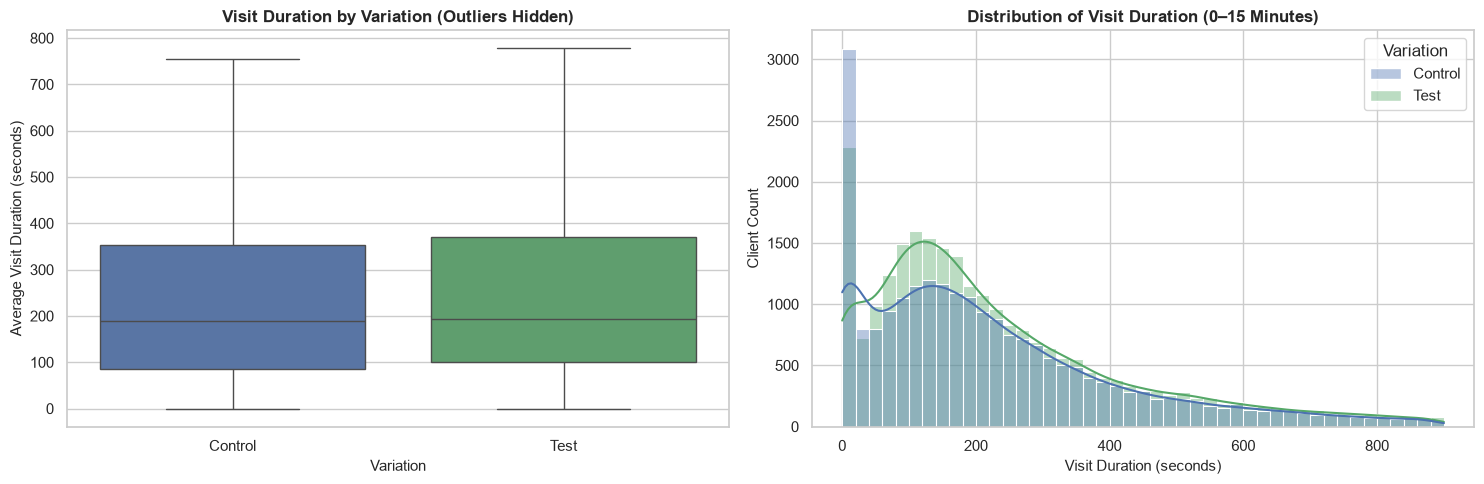

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Boxplot without extreme outlier dots
sns.boxplot(
    data=df_v1,
    x="Variation",
    y="average_visit_duration_seconds",
    order=["Control", "Test"],
    palette=PALETTE,
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title("Visit Duration by Variation (Outliers Hidden)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Variation", fontsize=11)
axes[0].set_ylabel("Average Visit Duration (seconds)", fontsize=11)

# Histogram zoomed to 0-15 minutes (900 seconds)
sns.histplot(
    data=df_v1[df_v1["average_visit_duration_seconds"] <= 900],
    x="average_visit_duration_seconds",
    hue="Variation",
    hue_order=["Control", "Test"],
    kde=True,
    bins=45,
    palette=PALETTE,
    alpha=0.4,
    ax=axes[1]
)
axes[1].set_title("Distribution of Visit Duration (0–15 Minutes)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Visit Duration (seconds)", fontsize=11)
axes[1].set_ylabel("Client Count", fontsize=11)

plt.tight_layout()
plt.savefig("visit_duration_distribution.png", dpi=300)
plt.show()

## 3. Step-Level Duration Analysis
To accurately measure how long users spend on each funnel step without deleting final exit events, we calculate `step_duration_seconds` strictly within each `visit_id`, filter out inactive timeouts ($> 1800\text{s}$) into a dedicated subset, and sum durations when a client visits the same step multiple times in a single session.

In [23]:
# 1. Calculate next timestamp and duration strictly per visit (leaving final steps intact in df_final_web_data)
df_final_web_data["next_date_time"] = df_final_web_data.groupby("visit_id")["date_time"].shift(-1)
df_final_web_data["step_duration_seconds"] = (
    df_final_web_data["next_date_time"] - df_final_web_data["date_time"]
).dt.total_seconds()

# 2. Filter out invalid or session-timeout durations (> 30 mins) into a separate DataFrame
valid_durations = df_final_web_data[
    (df_final_web_data["step_duration_seconds"] >= 0) &
    (df_final_web_data["step_duration_seconds"] <= 1800)
].copy()

# 3. Sum durations per visit per step (combines repeated views like 1 -> 2 -> 1)
visit_step_totals = (
    valid_durations.groupby(["visit_id", "Variation", "process_step"], dropna=False)["step_duration_seconds"]
    .sum()
    .reset_index()
)

# 4. Aggregate to final step summary
step_time_summary = (
    visit_step_totals.groupby(["process_step", "Variation"], dropna=False)["step_duration_seconds"]
    .agg(
        median_sec="median",
        mean_sec="mean",
        visit_count="count"
    )
    .reset_index()
)

display(step_time_summary)

,process_step,Variation,median_sec,mean_sec,visit_count
0,0,Control,25.0,82.838278,26224
1,0,Test,17.0,86.421051,30089
2,1,Control,25.0,58.755950,21049
3,1,Test,35.0,79.672311,26046
4,2,Control,82.0,115.871604,18918
5,2,Test,75.0,110.830207,23511
6,3,Control,89.0,162.618227,16591
7,3,Test,62.0,143.538816,20816
8,4,Control,70.0,202.169371,1541
9,4,Test,113.0,295.021026,3139


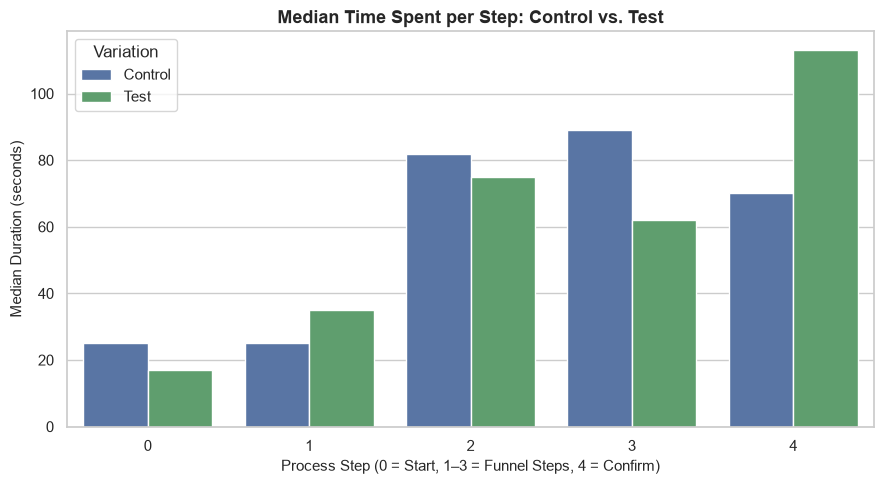

In [24]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=step_time_summary,
    x="process_step",
    y="median_sec",
    hue="Variation",
    hue_order=["Control", "Test"],
    palette=PALETTE
)

plt.title("Median Time Spent per Step: Control vs. Test", fontsize=13, fontweight="bold")
plt.xlabel("Process Step (0 = Start, 1–3 = Funnel Steps, 4 = Confirm)", fontsize=11)
plt.ylabel("Median Duration (seconds)", fontsize=11)
plt.legend(title="Variation")
plt.tight_layout()
plt.savefig("mediantime.png", dpi=300)
plt.show()

### Key Step-Duration Insights:
- **Quicker Initial Engagement (Step 0):** Users in the Test group take less time to initiate the process on Step 0 (**17.0s** vs. **25.0s** in Control), indicating the new landing page is clearer and more actionable.
- **Friction Point at Step 1:** Step 1 is the only pre-confirmation funnel stage where Test users spend more time than Control (**35.0s** vs. **25.0s**). This highlights Step 1 as an area for UX review (new prompts or initial adaptation to the new layout).
- **Significant Efficiency Gains in Later Stages (Steps 2 & 3):** Test users move through the critical decision-making steps faster, saving **7 seconds** on Step 2 (**75.0s** vs. **82.0s**) and **27 seconds** on Step 3 (**62.0s** vs. **89.0s**).
- **Confirmation Page Behavior (Step 4):** Step 4 durations are only recorded for the subset of visits where a user performed another click after reaching confirmation (3,139 in Test vs. 1,541 in Control).

## 4. Funnel Progression, Exit Step, & Backtracking Analysis
Here we evaluate two complementary views of the user journey:
1. **Standard Funnel Progression:** How many unique visits reached each milestone step (0 through 4) and the step-to-step drop-off rate.
2. **Literal Exit Step vs. Furthest Step Reached:** Where users actually ended their session (`.last()`) vs. the deepest step they reached (`.max()`), identifying sessions where users backtracked before abandoning.

In [25]:
# 1. Count unique visits reaching each step by Variation
funnel = (
    df_final_web_data.groupby(["process_step", "Variation"])["visit_id"]
    .nunique()
    .unstack("Variation")
)

# 2. Calculate Step-to-Step Drop-off Rate: (Current - Next) / Current * 100
funnel_dropoff = pd.DataFrame(index=funnel.index)
for col in funnel.columns:
    next_step_visits = funnel[col].shift(-1)
    funnel_dropoff[f"{col}_dropoff_pct"] = (
        (funnel[col] - next_step_visits) / funnel[col] * 100
    ).round(2)

funnel_summary = funnel.join(funnel_dropoff)
display(funnel_summary)

,Control,Test,Control_dropoff_pct,Test_dropoff_pct
process_step,,,,
0,30903,33144,23.82,14.69
1,23541,28274,14.49,13.37
2,20131,24493,9.13,9.44
3,18293,22180,12.32,2.05
4,16039,21725,NaN,NaN


In [26]:
# Build comprehensive visit-level summary comparing furthest step vs literal final step
visit_exit_analysis = (
    df_final_web_data.groupby(["visit_id", "Variation"], dropna=False)
    .agg(
        furthest_step=("process_step", "max"),    # Deepest funnel step reached
        final_step=("process_step", "last"),      # Literal screen the user exited on
        total_actions=("process_step", "count"),  # Total pageviews/clicks in visit
        unique_steps=("process_step", "nunique")  # Distinct steps visited
    )
    .reset_index()
)

# Flag visits where the user backtracked and exited on an earlier step
visit_exit_analysis["backtracked_before_exit"] = (
    visit_exit_analysis["final_step"] < visit_exit_analysis["furthest_step"]
)
visit_exit_analysis["has_repeated_steps"] = (
    visit_exit_analysis["total_actions"] > visit_exit_analysis["unique_steps"]
)

# Export clean CSVs for Tableau
visit_exit_analysis.to_csv("visit_exit_analysis.csv", index=False)
df_final_web_data.to_csv("df_final_web_data_tableau.csv", index=False)

# Cross-tabulate literal exit step counts and percentages
dropoff_counts = pd.crosstab(
    visit_exit_analysis["final_step"],
    visit_exit_analysis["Variation"],
    margins=True,
    margins_name="Total"
)

dropoff_rates = (
    pd.crosstab(
        visit_exit_analysis["final_step"],
        visit_exit_analysis["Variation"],
        normalize="columns"
    ) * 100
).round(2)

print("--- Literal Final Step (Exit Point vs. Completion) Counts ---")
display(dropoff_counts)
print("--- Literal Final Step Percentages (%) ---")
display(dropoff_rates)

--- Literal Final Step (Exit Point vs. Completion) Counts ---


Variation,Control,Test,Total
final_step,,,
0,9641,9445,19086
1,3496,3136,6632
2,1459,1322,2781
3,2250,1782,4032
4,15335,21437,36772
Total,32181,37122,69303


--- Literal Final Step Percentages (%) ---


Variation,Control,Test
final_step,,
0,29.96,25.44
1,10.86,8.45
2,4.53,3.56
3,6.99,4.80
4,47.65,57.75


In [27]:
# 1. Ensure strict chronological sorting within each visit
df_final_web_data['date_time'] = pd.to_datetime(df_final_web_data['date_time'])
df_sorted = df_final_web_data.sort_values(
    by=['visit_id', 'date_time'], 
    kind='mergesort'
).reset_index(drop=True)

# 2. Assign the literal exit step (last screen viewed per visit) back to every row
df_sorted['exit_step'] = df_sorted.groupby('visit_id')['process_step'].transform('last')

# 3. Create the visit_exit_analysis summary table
visit_exit_analysis = (
    df_sorted.groupby(['visit_id', 'Variation'], dropna=False)
    .agg(
        furthest_step=('process_step', 'max'),
        exit_step=('process_step', 'last'),
        total_actions=('process_step', 'count'),
        unique_steps=('process_step', 'nunique')
    )
    .reset_index()
)

display(visit_exit_analysis.head())

,visit_id,Variation,furthest_step,exit_step,total_actions,unique_steps
0,100012776_37918976071_457913,Test,4,4,2,1
1,100019538_17884295066_43909,Test,4,4,11,5
2,100022086_87870757897_149620,Test,4,4,5,5
3,100030127_47967100085_936361,Control,0,0,1,1
4,100037962_47432393712_705583,Control,1,0,4,2


In [33]:
#checking if the calculation worked
df_final_web_data.loc[df_final_web_data["client_id"] == 7338123].sort_values(
    by=["visit_id", "date_time"], 
    ascending=[True, True]
).reset_index(drop=True)

,client_id,visitor_id,visit_id,process_step,date_time,year,month,day,time,Variation,weekday,next_date_time,step_duration_seconds
0,7338123,612065484_94198474375,100019538_17884295066_43909,0,2017-04-09 16:20:56,2017,4,9,16:20:56,Test,Sunday,2017-04-09 16:21:12,16.0
1,7338123,612065484_94198474375,100019538_17884295066_43909,1,2017-04-09 16:21:12,2017,4,9,16:21:12,Test,Sunday,2017-04-09 16:21:21,9.0
2,7338123,612065484_94198474375,100019538_17884295066_43909,2,2017-04-09 16:21:21,2017,4,9,16:21:21,Test,Sunday,2017-04-09 16:21:35,14.0
3,7338123,612065484_94198474375,100019538_17884295066_43909,1,2017-04-09 16:21:35,2017,4,9,16:21:35,Test,Sunday,2017-04-09 16:21:41,6.0
4,7338123,612065484_94198474375,100019538_17884295066_43909,1,2017-04-09 16:21:41,2017,4,9,16:21:41,Test,Sunday,2017-04-09 16:21:45,4.0
5,7338123,612065484_94198474375,100019538_17884295066_43909,0,2017-04-09 16:21:45,2017,4,9,16:21:45,Test,Sunday,2017-04-09 16:21:59,14.0
6,7338123,612065484_94198474375,100019538_17884295066_43909,0,2017-04-09 16:21:59,2017,4,9,16:21:59,Test,Sunday,2017-04-09 16:22:04,5.0
7,7338123,612065484_94198474375,100019538_17884295066_43909,1,2017-04-09 16:22:04,2017,4,9,16:22:04,Test,Sunday,2017-04-09 16:22:08,4.0
8,7338123,612065484_94198474375,100019538_17884295066_43909,2,2017-04-09 16:22:08,2017,4,9,16:22:08,Test,Sunday,2017-04-09 16:24:01,113.0
9,7338123,612065484_94198474375,100019538_17884295066_43909,3,2017-04-09 16:24:01,2017,4,9,16:24:01,Test,Sunday,2017-04-09 16:24:58,57.0


ValueError: Could not interpret value `final_step` for `x`. An entry with this name does not appear in `data`.

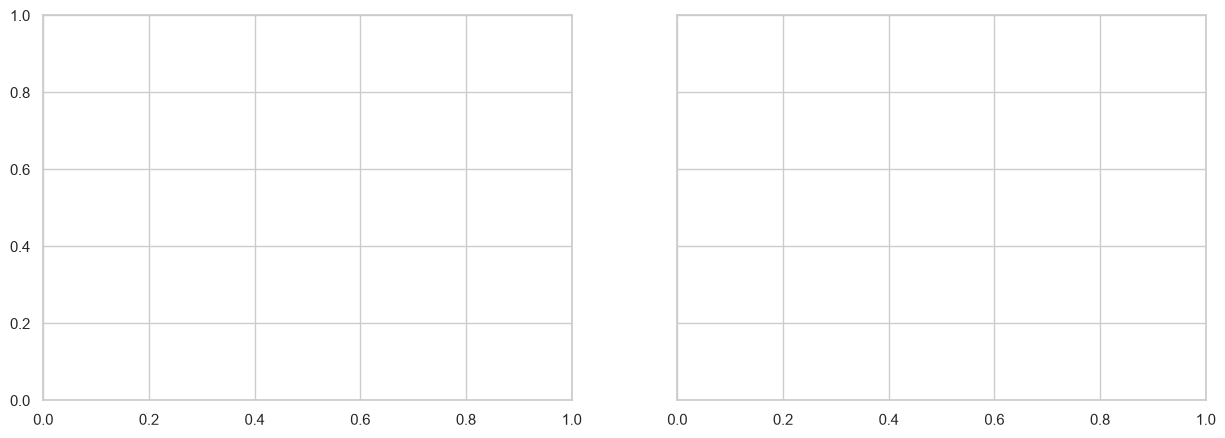

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Plot 1: Literal Final Step (Last screen before leaving)
sns.countplot(
    data=visit_exit_analysis,
    x="final_step",
    hue="Variation",
    hue_order=["Control", "Test"],
    palette=PALETTE,
    ax=axes[0]
)
axes[0].set_title("Literal Exit Step per Visit (Last Screen Viewed)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Final Step (0–3 = Abandoned, 4 = Completed)", fontsize=11)
axes[0].set_ylabel("Number of Visits", fontsize=11)

# Plot 2: Furthest Step Reached per Visit
sns.countplot(
    data=visit_exit_analysis,
    x="furthest_step",
    hue="Variation",
    hue_order=["Control", "Test"],
    palette=PALETTE,
    ax=axes[1]
)
axes[1].set_title("Furthest Step Reached per Visit (Max Milestone)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Furthest Step (0–3 = Abandoned, 4 = Completed)", fontsize=11)
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("dropoff_comparison.png", dpi=300)
plt.show()

### Funnel & Exit Takeaways:
- **Substantial Lift in Session Completion (Step 4):** In the Test variation, **57.75%** of all visits ended on the Confirmation step (21,437 visits), compared to **47.65%** in Control (15,335 visits)—a **+10.10 percentage point increase** at the session level.
- **Lower Early Bounce Rate (Step 0):** Only **25.44%** of Test visits abandoned on Step 0, compared to **29.96%** in Control.
- **Reduced Mid-Funnel Drop-offs:** Test consistently reduced abandonment across Steps 1, 2, and 3 compared to Control.

## 5. Statistical Hypothesis Testing
### 5.1 Completion Rate Hypothesis (Two-Sample Proportions Z-Test)
- **Null Hypothesis ($H_0$):** $p_{\text{Test}} = p_{\text{Control}}$ (Client completion rate is equal across both groups)
- **Alternative Hypothesis ($H_1$):** $p_{\text{Test}} \neq p_{\text{Control}}$ (Client completion rate differs significantly between groups)

In [ ]:
# A client completed if they have at least 1 completed visit (completed_visits > 0)
control_clients = df_v1[df_v1["Variation"] == "Control"]
test_clients = df_v1[df_v1["Variation"] == "Test"]

control_successes = (control_clients["completed_visits"] > 0).sum()
test_successes = (test_clients["completed_visits"] > 0).sum()

control_total = len(control_clients)
test_total = len(test_clients)

print(f"Control Completion: {control_successes:,} / {control_total:,} ({control_successes/control_total:.2%})")
print(f"Test Completion:    {test_successes:,} / {test_total:,} ({test_successes/test_total:.2%})")

count = np.array([test_successes, control_successes])
nobs = np.array([test_total, control_total])

z_stat, p_value = proportions_ztest(count=count, nobs=nobs, alternative="two-sided")

print(f"\nZ-statistic: {z_stat:.4f}")
print(f"P-value:     {p_value:.4e}")

**Result:** Reject $H_0$ ($p = 5.96 \times 10^{-19} < 0.001$). The Test variation achieved a highly statistically significant increase in client completion rate compared to the Control group.

### 5.2 Visit Duration Hypothesis (Mann-Whitney U Test)
Because visit durations are heavily right-skewed, we use the non-parametric **Mann-Whitney U test**.
- **Null Hypothesis ($H_0$):** The distribution of visit duration is the same between Control and Test.
- **Alternative Hypothesis ($H_1$):** Test users spend significantly more time than Control users.

In [ ]:
test_time = df_v1.loc[
    df_v1["Variation"] == "Test", "average_visit_duration_seconds"
].dropna()

control_time = df_v1.loc[
    df_v1["Variation"] == "Control", "average_visit_duration_seconds"
].dropna()

u_stat, p_val_greater = mannwhitneyu(control_time, test_time, alternative="less")

print("--- One-Sided Mann-Whitney U Test (Test > Control) ---")
print(f"U-Statistic: {u_stat:,.2f}")
print(f"P-value:     {p_val_greater:.4e}")

alpha = 0.05
if p_val_greater < alpha:
    print(f"\nReject H0 (p = {p_val_greater:.4e} < {alpha}): Test users spent significantly more time overall than Control users.")
else:
    print(f"\nFail to reject H0 (p = {p_val_greater:.4e} >= {alpha}): No significant evidence that Test users spent more time.")

## 6. Sample Ratio Mismatch, Temporal, & Demographic Cohort Analysis

In [ ]:
print("--- Client Split by Variation (Sample Ratio Check) ---")
display((df_v1["Variation"].value_counts(normalize=True) * 100).round(2))

print("\n--- Web Events Distribution by Weekday (%) ---")
display((df_final_web_data["weekday"].value_counts(normalize=True) * 100).round(2))

In [ ]:
# Create age groups
df_v1["age_group"] = pd.cut(
    df_v1["clnt_age"],
    bins=[0, 35, 55, 120],
    labels=["< 35", "35–54", "55+"],
    right=False
)

age_summary = (
    df_v1.groupby(["age_group", "Variation"], observed=False)
    .agg(
        completion_rate=("completed_visits", lambda x: (x > 0).mean() * 100),
        median_duration=("average_visit_duration_seconds", "median")
    )
    .round(2)
    .unstack()
)

display(age_summary)

### Age Cohort Takeaways:
- **Younger clients (< 35) drove the strongest lift:** Completion rate surged by **+5.09 percentage points** (from **67.58%** to **72.67%**), exceeding Vanguard's 5% threshold without increasing median visit duration (~153s).
- **Older clients (55+) experienced added friction:** While their completion rate rose by **+3.82 percentage points** (**62.39%** to **66.21%**), their median session duration increased by **21 seconds** (**219s** to **240s**), indicating adaptation effort on the new interface.
- **Middle cohort (35–54) showed moderate lift:** Completion rose by **+2.41 percentage points** (**67.30%** to **69.71%**), with median duration remaining steady (~192s–193s).

In [37]:
# 1. Create age groups based on clnt_age
df_v1['age_group'] = pd.cut(
    df_v1['clnt_age'],
    bins=[0, 35, 55, 120],
    labels=['< 35', '35–54', '55+'],
    right=False
)

# 2. Save your updated demographic dataset so Tableau can read the new column
df_v1.to_csv('./Data Cleaning/df_v1.csv', index=False)